# PCA: full price-model numerical features

Compare the scree elbow with the first count explaining strictly more than 85% of numerical variance. Neither measures price accuracy or selects a PCR count. Runs write fresh artifacts under `MODEL_OUTPUT/pca/`.

## 1. Methods

Only fit-partition rows fit medians, scaling, and unwhitened PCA. Entirely missing and constant fields are excluded; flags, categories, and missingness indicators bypass PCA. Listings have equal weight, including repeated make/family values and correlated representations.

The elbow maximizes normalized distance from the scree endpoint chord; degenerate spectra are inconclusive. The >85% crossing is a separate reference. Enrichment dates remain retrospective.

References: [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [PCR limitations](https://scikit-learn.org/stable/auto_examples/cross_decomposition/plot_pcr_vs_pls.html).

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import gc, hashlib, importlib.metadata, json, sys, time
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "MODELS/Price_ML_Models.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "MODELS/Price_ML_Models.py").is_file():
    raise FileNotFoundError("Run this notebook from the project checkout.")
sys.path.insert(0, str(PROJECT_ROOT))
from MODELS import Price_ML_Models as price
from EDA.DATA_CLEANING import FINAL_DATASET_PATH, DEFAULT_COHORT_REVIEW_DIR

SAMPLE_SIZE = None  # None: every eligible listing; an integer is an explicitly labeled pilot.
VARIANCE_REFERENCE = 0.85
EXPERT_FEATURE_DIR = price.EXPERT_FEATURE_DIRECTORY
STARTED = time.perf_counter()
RUN_DIR = PROJECT_ROOT / "MODEL_OUTPUT/pca" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN = "#315E88", "#AB5C16", "#28745C"

def write_json(name, value):
    (RUN_DIR / name).write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")

def save_figure(fig, name):
    fig.savefig(RUN_DIR / name, dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()

def strict_variance_count(ratios, threshold=0.85):
    cumulative = np.cumsum(ratios)
    positions = np.flatnonzero(cumulative > threshold)
    if not len(positions):
        raise ValueError("The requested variance threshold was not reached.")
    return int(positions[0] + 1)

def scree_elbow(eigenvalues):
    values = np.asarray(eigenvalues, dtype=float)
    if len(values) < 3 or not np.isfinite(values).all() or np.isclose(values[0], values[-1]):
        return None, np.zeros(len(values)), "Inconclusive: insufficient or flat spectrum."
    x = np.linspace(0, 1, len(values))
    y = (values - values[-1]) / (values[0] - values[-1])
    distances = np.abs(x + y - 1) / np.sqrt(2)
    distances[[0, -1]] = 0
    if distances.max() <= 1e-3:
        return None, distances, "Inconclusive: approximately linear normalized spectrum."
    return int(np.argmax(distances) + 1), distances, "Geometric candidate only; assess the scree curve visually."

metadata = {"status": "running", "created_at": datetime.now(timezone.utc).isoformat(),
            "model_type": "full", "sample_size": SAMPLE_SIZE, "fit_partition_only": True,
            "split_strategy": "unseen_family", "split_seed": price.RANDOM_SEED,
            "variance_reference": VARIANCE_REFERENCE, "component_count_adopted": None,
            "package_versions": {p: importlib.metadata.version(p) for p in
                                 ("numpy", "pandas", "polars", "scikit-learn", "pyarrow")}}
write_json("manifest.json", metadata)


## 2. Freeze sources and load features

Price affects existing eligibility rules only; it never enters PCA.

In [2]:
review_files = sorted(DEFAULT_COHORT_REVIEW_DIR.glob("*/cohort_outlier_candidates.csv"))
if not review_files:
    raise FileNotFoundError("Create the existing cohort review before running PCA.")
review_path = review_files[-1]
source_paths = [FINAL_DATASET_PATH / name for name in (
    "used_cars.parquet", "NHTSA_vPIC.parquet", "NHTSA_Complaints.parquet",
    "NHTSA_Recalls.parquet", "NHTSA_Safety.parquet")]
source_paths += [price.YOUTUBE_FEATURE_DIRECTORY / name for name in
                 ("make_features.parquet", "price_feature_manifest.json")]
source_paths += [EXPERT_FEATURE_DIR / name for name in
                 ("cohort_features.parquet", "make_features.parquet", "expert_feature_manifest.json", "review_resolution.parquet")]
source_paths.append(review_path)
source_stats = {str(p): (p.stat().st_size, p.stat().st_mtime_ns) for p in source_paths}
source_hashes = {str(p.relative_to(PROJECT_ROOT)): price.file_sha256(p) for p in source_paths}
metadata["source_file_sha256"] = source_hashes
metadata["dataset_fingerprint"] = hashlib.sha256(json.dumps(source_hashes, sort_keys=True).encode()).hexdigest()
code_paths = [PROJECT_ROOT / p for p in ("MODELS/Price_ML_Models.py", "EDA/DATA_CLEANING.py",
                                       "NHTSA/text_features.py", "EXPERT_REVIEWS/price_features.py")]
metadata["loader_code_sha256"] = {str(p.relative_to(PROJECT_ROOT)): price.file_sha256(p) for p in code_paths}
frame, data_info = price.load_model_frame("full", SAMPLE_SIZE, expert_feature_dir=EXPERT_FEATURE_DIR)
if any((p.stat().st_size, p.stat().st_mtime_ns) != source_stats[str(p)] for p in source_paths):
    raise RuntimeError("A source changed while loading. Rerun against a stable snapshot.")
if sorted(DEFAULT_COHORT_REVIEW_DIR.glob("*/cohort_outlier_candidates.csv"))[-1] != review_path:
    raise RuntimeError("The cohort policy changed while loading; start a new run.")
write_json("data_info.json", data_info)
write_json("manifest.json", metadata)


## 3. Partitions and field inventory

The seed-42 split holds out year/make/model families with all trims together. Held-out rows appear only in the split receipt.

In [3]:
features = list(price.MODEL_FEATURE_SETS["full"])
categorical = [c for c in features if frame.schema[c] == pl.String]
numeric = [c for c in features if c not in categorical]
binary_flags = set(price.OPTION_LABELS) | {
    "complaint_source_records_present", "recall_source_records_present",
    "yt_feature_row_present", "yt_support_suppressed", "yt_semantic_missing",
    "doug_cohort_match_available", "doug_make_baseline_available",
} | {f"yt_{a}_topic_missing" for a in price.YOUTUBE_ASPECTS} | {
    f"yt_{a}_missing" for a in ("comfort", "maintenance_cost", "performance", "reliability")
}
candidates = [c for c in numeric if c not in binary_flags]
if (len(features), len(categorical), len(binary_flags), len(candidates)) != (173, 53, 28, 92):
    raise ValueError("The full schema changed. Review the explicit PCA field roles before proceeding.")
if not binary_flags.issubset(numeric):
    raise ValueError("A registered numerical flag changed type or disappeared.")

def source_block(field):
    if field in price.YOUTUBE_FEATURE_COLUMNS: return "YouTube"
    if field in price.EXPERT_FEATURE_COLUMNS: return "DougScore"
    if field in price.BASE_FEATURE_COLUMNS: return "Listing / derived listing"
    if field in price.COMPLAINT_RECALL_FEATURE_COLUMNS: return "NHTSA aggregates"
    return "vPIC"

inventory = pd.DataFrame([{"field": c, "dtype": str(frame.schema[c]), "source_block": source_block(c),
    "role": "PCA candidate" if c in candidates else "Retain binary flag" if c in binary_flags else "Retain category"}
    for c in features])
inventory.to_csv(RUN_DIR / "feature_inventory.csv", index=False)
with pd.option_context("display.max_rows", 180):
    display(inventory)
display(inventory.groupby(["source_block", "role"]).size().unstack(fill_value=0))

groups = frame["_cohort_group"].to_numpy()
fit_index, validation_index, test_index, split_info = price.split_by_vehicle_cohort(groups)
group_sets = [set(groups[idx]) for idx in (fit_index, validation_index, test_index)]
assert all(group_sets[i].isdisjoint(group_sets[j]) for i in range(3) for j in range(i + 1, 3))
assert len(fit_index) + len(validation_index) + len(test_index) == frame.height
partition = np.full(frame.height, "fit", dtype="<U10")
partition[validation_index], partition[test_index] = "validation", "test"
receipt = frame.select("vin", *price.COHORT_COLUMNS, "_cohort_group").rename({"_cohort_group": "split_group"})
receipt = receipt.with_columns(pl.Series("partition", partition))
receipt.write_parquet(RUN_DIR / "split_manifest.parquet")
fingerprint_input = receipt.select("vin", "partition", "split_group").to_pandas()
metadata["split_fingerprint"] = price.split_fingerprint(fingerprint_input)
metadata["partition_rows"] = {p: len(idx) for p, idx in zip(("fit", "validation", "test"),
    (fit_index, validation_index, test_index))}
metadata["partition_groups"] = {p: len(g) for p, g in zip(("fit", "validation", "test"), group_sets)}
metadata["split_details"] = split_info
display(pd.DataFrame({"rows": metadata["partition_rows"], "groups": metadata["partition_groups"]}))
del fingerprint_input, receipt, groups, group_sets, partition
gc.collect()

,field,dtype,source_block,role
0,engine_displacement,Float64,Listing / derived listing,PCA candidate
1,engine_type,String,Listing / derived listing,Retain category
2,exterior_color,String,Listing / derived listing,Retain category
3,fuel_type,String,Listing / derived listing,Retain category
4,horsepower,Float64,Listing / derived listing,PCA candidate
5,interior_color,String,Listing / derived listing,Retain category
6,is_new,String,Listing / derived listing,Retain category
7,listing_color,String,Listing / derived listing,Retain category
8,make_name,String,Listing / derived listing,Retain category
9,mileage,Float64,Listing / derived listing,PCA candidate


role,PCA candidate,Retain binary flag,Retain category
source_block,,,
DougScore,11,2,1
Listing / derived listing,13,9,17
NHTSA aggregates,18,2,0
YouTube,31,15,0
vPIC,19,0,35


,rows,groups
fit,1720358,6141
validation,496219,1536
test,576422,1920


60

## 4. Fit-only coverage and preprocessing

Nonfinite values become missing. Sparse varying fields remain; median imputation can shape correlations.

In [4]:
fit_numbers = frame.select(candidates)[fit_index].with_columns([
    pl.when(pl.col(c).is_finite()).then(pl.col(c).cast(pl.Float64)).otherwise(None).alias(c)
    for c in candidates])
coverage = frame.select(sorted(binary_flags))[fit_index].select([
    pl.col(c).cast(pl.Float64).mean().alias(c) for c in sorted(binary_flags)]).to_pandas().T
coverage.columns = ["observed_true_share"]
coverage["observed_rows"] = [int(frame[c][fit_index].count()) for c in coverage.index]
coverage["fit_rows"] = len(fit_index)
coverage.index.name = "field"
coverage.to_csv(RUN_DIR / "flag_coverage.csv")
display(coverage.round(4))
expert_coverage = frame.select("doug_source_level")[fit_index].group_by("doug_source_level").len().to_pandas()
expert_coverage["fit_share"] = expert_coverage["len"] / len(fit_index)
display(expert_coverage)
expert_coverage.to_csv(RUN_DIR / "expert_coverage.csv", index=False)

profile = pd.DataFrame({"field": candidates,
    "observed_rows": [fit_numbers[c].count() for c in candidates],
    "minimum": [fit_numbers[c].min() for c in candidates],
    "maximum": [fit_numbers[c].max() for c in candidates]})
profile["missing_pct"] = 100 * (1 - profile.observed_rows / len(fit_index))
profile["status"] = np.where(profile.observed_rows.eq(0), "excluded_all_missing",
                             np.where(profile.minimum.eq(profile.maximum), "excluded_constant", "included"))
retained = profile.loc[profile.status.eq("included"), "field"].tolist()
if len(retained) < 2 or len(fit_index) <= len(retained):
    raise ValueError("Insufficient nonconstant fit data for the full PCA spectrum.")
del frame
gc.collect()
matrix = fit_numbers.select(retained).to_numpy(writable=True)
del fit_numbers
gc.collect()
imputer = SimpleImputer(strategy="median", copy=False)
matrix = imputer.fit_transform(matrix)
scaler = StandardScaler(copy=False)
matrix = scaler.fit_transform(matrix)
assert np.isfinite(matrix).all()
assert np.allclose(matrix.mean(axis=0), 0, atol=1e-7)
assert np.allclose(matrix.var(axis=0), 1, atol=1e-7)
profile = profile.set_index("field")
profile.loc[retained, "imputation_median"] = imputer.statistics_
profile.loc[retained, "imputed_mean"] = scaler.mean_
profile.loc[retained, "imputed_standard_deviation"] = scaler.scale_
profile = profile.reset_index()
profile.to_csv(RUN_DIR / "numerical_profile.csv", index=False)
display(profile.sort_values("missing_pct", ascending=False).head(20).round(3))
display(profile.loc[~profile.status.eq("included"), ["field", "status", "observed_rows"]])
metadata.update(pca_candidate_fields=candidates, pca_retained_fields=retained,
                excluded_fields=profile.loc[~profile.status.eq("included"), ["field", "status"]].to_dict("records"),
                fit_rows=len(fit_index), fit_groups=metadata["partition_groups"]["fit"],
                numerical_binary_flags=sorted(binary_flags), categorical_fields=categorical)
write_json("manifest.json", metadata)


,observed_true_share,observed_rows,fit_rows
field,,,
complaint_source_records_present,0.8597,1720358,1720358
doug_cohort_match_available,0.0862,1720358,1720358
doug_make_baseline_available,0.7470,1720358,1720358
option_adaptive_cruise,0.1753,1600158,1720358
option_alloy_wheels,0.6443,1600158,1720358
option_backup_camera,0.7781,1600158,1720358
option_bluetooth,0.6908,1600158,1720358
option_heated_seats,0.4279,1600158,1720358
option_leather,0.2873,1600158,1720358


,doug_source_level,len,fit_share
0,cohort,148330,0.086220
1,make_average,1171083,0.680721
2,missing,400945,0.233059


,field,observed_rows,minimum,maximum,missing_pct,status,imputation_median,imputed_mean,imputed_standard_deviation
69,yt_comfort_video_balanced_net,0,NaN,NaN,100.000,excluded_all_missing,NaN,NaN,NaN
72,yt_maintenance_cost_video_balanced_net,0,NaN,NaN,100.000,excluded_all_missing,NaN,NaN,NaN
75,yt_performance_video_balanced_net,0,NaN,NaN,100.000,excluded_all_missing,NaN,NaN,NaN
30,ChargerPowerKW,552,10.0,150.0,99.968,included,150.0,149.993,0.892
27,BatteryKWh,1741,2.0,81.0,99.899,included,12.0,12.008,0.595
26,BedLengthIN,3606,60.0,97.0,99.790,included,61.0,61.008,0.323
31,EngineKW,5049,28.0,470.0,99.707,included,135.0,135.014,4.207
29,BatteryV,7842,4.0,375.0,99.544,included,4.0,4.510,12.294
28,BatteryPacks,11877,1.0,2.0,99.310,included,1.0,1.000,0.018
25,Windows,58475,4.0,6.0,96.601,included,4.0,4.002,0.059


,field,status,observed_rows
69,yt_comfort_video_balanced_net,excluded_all_missing,0
72,yt_maintenance_cost_video_balanced_net,excluded_all_missing,0
75,yt_performance_video_balanced_net,excluded_all_missing,0
78,yt_reliability_video_balanced_net,excluded_constant,138474


## 5. PCA spectrum and selection diagnostics

In [5]:
sklearn_version = tuple(int(p) for p in importlib.metadata.version("scikit-learn").split(".")[:2])
solver = "covariance_eigh" if sklearn_version >= (1, 5) else "full"
pca = PCA(n_components=None, svd_solver=solver, whiten=False)
pca.fit(matrix)
n_fit, n_fields = matrix.shape
del matrix
gc.collect()
eigenvalues = pca.explained_variance_
ratios = pca.explained_variance_ratio_
cumulative = np.cumsum(ratios)
k85 = strict_variance_count(ratios, VARIANCE_REFERENCE)
elbow_k, elbow_distances, elbow_status = scree_elbow(eigenvalues)
spectrum = pd.DataFrame({"component": np.arange(1, n_fields + 1), "eigenvalue": eigenvalues,
    "explained_variance_pct": ratios * 100, "cumulative_variance_pct": cumulative * 100,
    "remaining_variance_pct": np.maximum(0, 1 - cumulative) * 100,
    "normalized_chord_distance": elbow_distances})
spectrum.to_csv(RUN_DIR / "spectrum.csv", index=False)
with pd.option_context("display.max_rows", 100):
    display(spectrum.round(4))


,component,eigenvalue,explained_variance_pct,cumulative_variance_pct,remaining_variance_pct,normalized_chord_distance
0,1,12.8005,14.5460,14.5460,85.4540,0.0000
1,2,8.7083,9.8958,24.4418,75.5582,0.2179
2,3,6.4215,7.2972,31.7390,68.2610,0.3361
3,4,5.5176,6.2700,38.0090,61.9910,0.3779
4,5,4.9354,5.6084,43.6173,56.3827,0.4020
5,6,3.3093,3.7606,47.3779,52.6221,0.4837
6,7,2.8340,3.2204,50.5984,49.4016,0.5018
7,8,2.6395,2.9994,53.5978,46.4022,0.5044
8,9,2.0793,2.3628,55.9606,44.0394,0.5272
9,10,1.8689,2.1238,58.0844,41.9156,0.5307


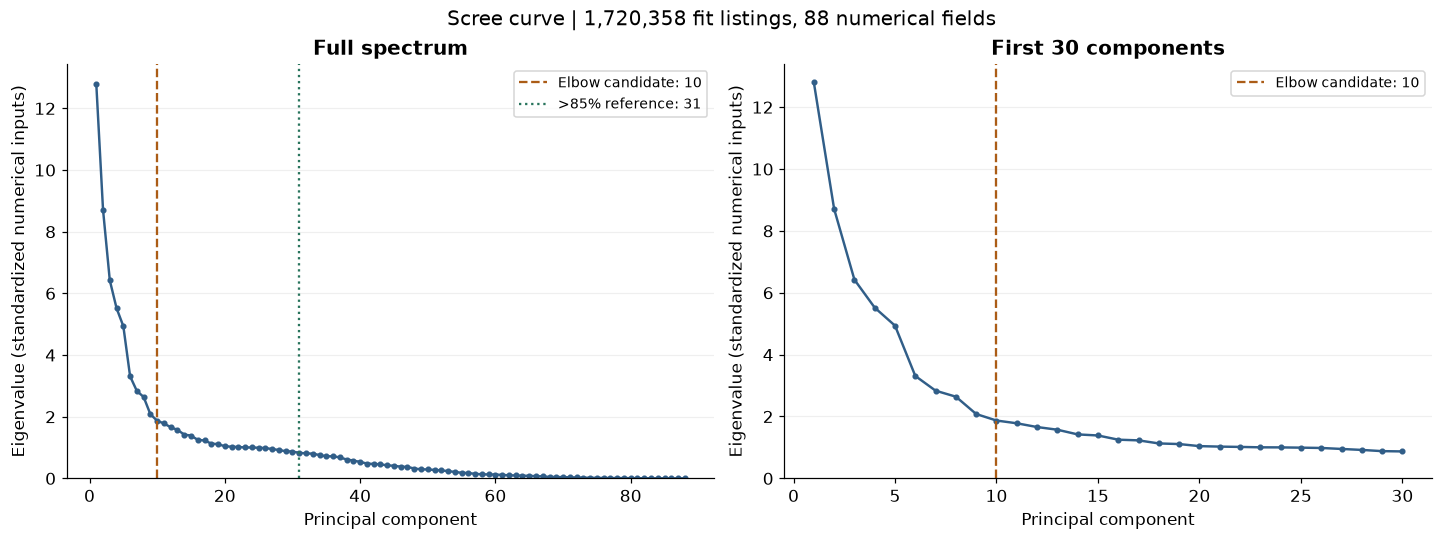

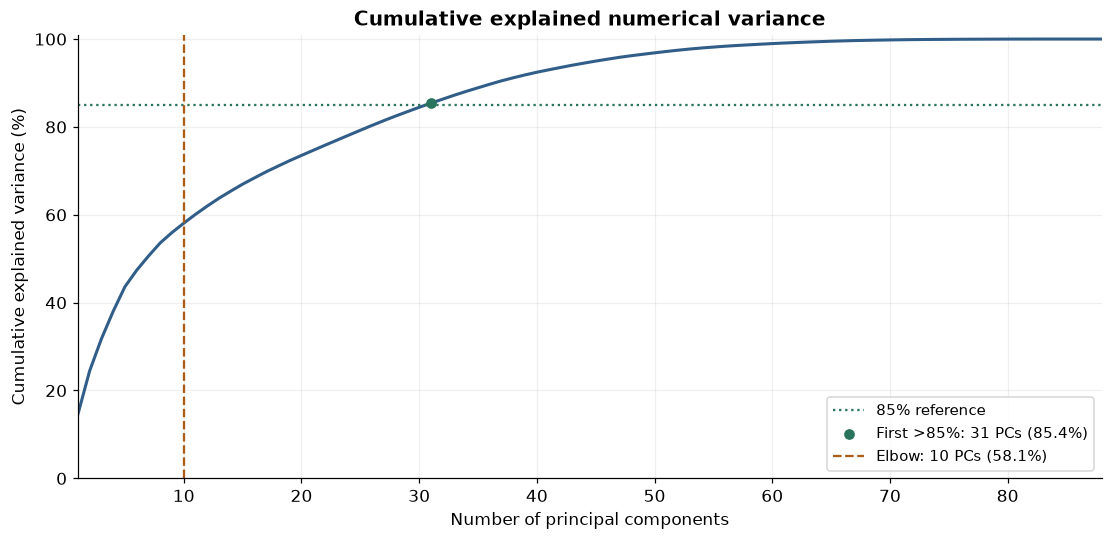

,diagnostic,components,cumulative_variance_pct,numerical_dimension_reduction_pct
0,Scree elbow candidate,10,58.08,88.64
1,First strictly >85%,31,85.40,64.77


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for ax, limit, title in zip(axes, (n_fields, min(30, n_fields)), ("Full spectrum", "First 30 components")):
    part = spectrum.iloc[:limit]
    ax.plot(part.component, part.eigenvalue, color=BLUE, marker="o", markersize=3, linewidth=1.6)
    if elbow_k is not None and elbow_k <= limit:
        ax.axvline(elbow_k, color=ORANGE, linestyle="--", label=f"Elbow candidate: {elbow_k}")
    if k85 <= limit:
        ax.axvline(k85, color=GREEN, linestyle=":", label=f">85% reference: {k85}")
    ax.set(title=title, xlabel="Principal component", ylabel="Eigenvalue (standardized numerical inputs)")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=.2)
    if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=9)
fig.suptitle(f"Scree curve | {n_fit:,} fit listings, {n_fields} numerical fields", fontsize=13)
save_figure(fig, "scree.png")

fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
ax.plot(spectrum.component, spectrum.cumulative_variance_pct, color=BLUE, linewidth=2)
ax.axhline(85, color=GREEN, linestyle=":", label="85% reference")
ax.scatter([k85], [cumulative[k85 - 1] * 100], color=GREEN, zorder=3,
           label=f"First >85%: {k85} PCs ({cumulative[k85 - 1]:.1%})")
if elbow_k is not None:
    ax.axvline(elbow_k, color=ORANGE, linestyle="--",
               label=f"Elbow: {elbow_k} PCs ({cumulative[elbow_k - 1]:.1%})")
ax.set(title="Cumulative explained numerical variance", xlabel="Number of principal components",
       ylabel="Cumulative explained variance (%)", ylim=(0, 101), xlim=(1, n_fields))
ax.grid(alpha=.2)
ax.legend(loc="lower right", fontsize=10)
save_figure(fig, "cumulative_variance.png")

selection_rows = []
for label, count in (("Scree elbow candidate", elbow_k), ("First strictly >85%", k85)):
    selection_rows.append({"diagnostic": label, "components": count,
        "cumulative_variance_pct": cumulative[count - 1] * 100 if count else None,
        "numerical_dimension_reduction_pct": (1 - count / n_fields) * 100 if count else None})
selection = pd.DataFrame(selection_rows)
selection.to_csv(RUN_DIR / "selection_diagnostics.csv", index=False)
display(selection.round(2))

## 6. Component interpretation

Weights apply to standardized fields; correlations describe field/component association. Signs are arbitrary. Neither establishes predictive or causal importance.

,component,field,weight,correlation
0,PC1,yt_maintenance_cost_mention_share,0.247,0.884
1,PC1,yt_comfort_mention_share,0.245,0.876
2,PC1,yt_reliability_mention_share,0.243,0.869
3,PC1,yt_design_mention_share,0.241,0.862
4,PC1,yt_technology_mention_share,0.239,0.855
5,PC1,yt_safety_mention_share,0.221,0.792
6,PC1,yt_semantic_03,-0.217,-0.777
7,PC1,yt_fuel_economy_range_mention_share,0.211,0.754
8,PC2,yt_eligible_count,0.267,0.787
9,PC2,yt_comment_count,0.266,0.786


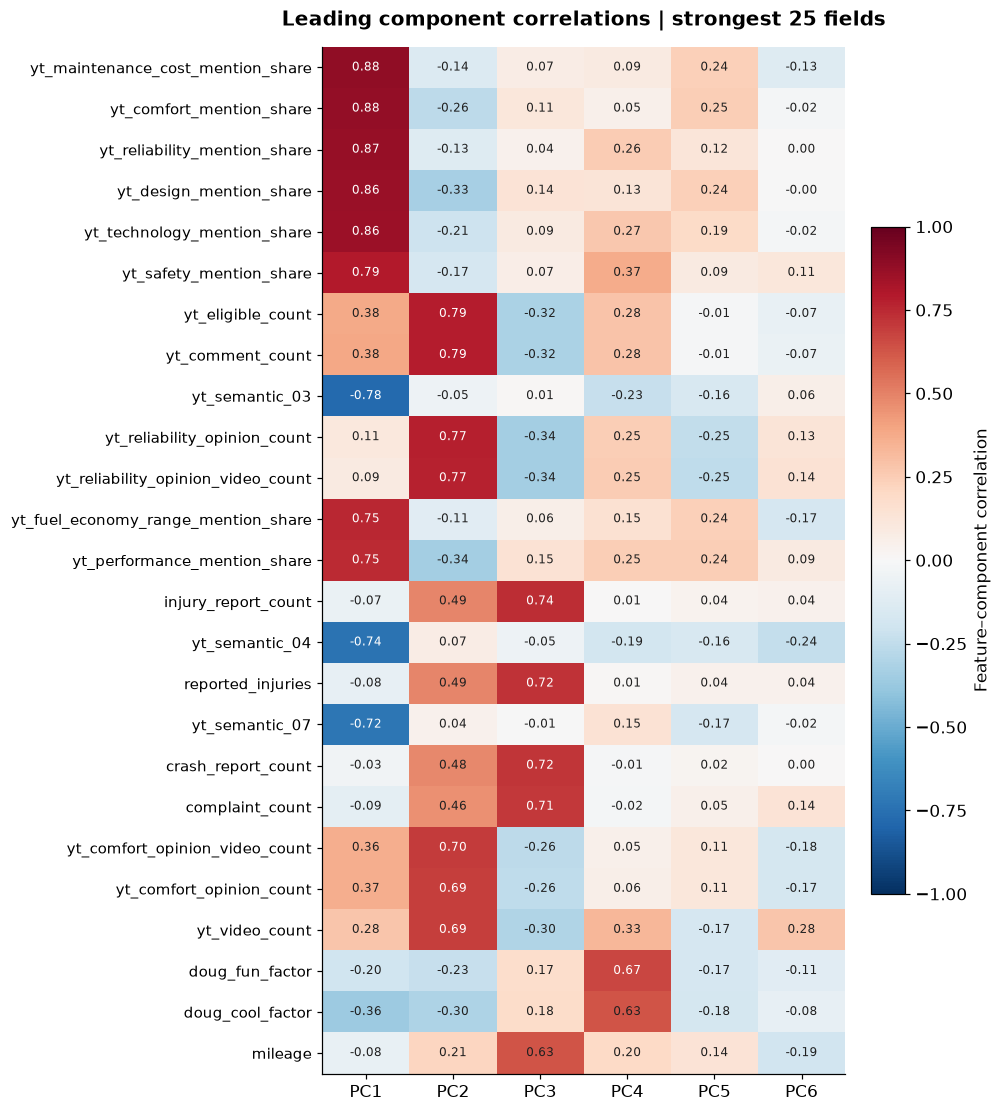

In [7]:
component_names = [f"PC{i}" for i in range(1, n_fields + 1)]
weights = pd.DataFrame(pca.components_.T, index=retained, columns=component_names)
weights.index.name = "field"
# PCA eigenvalues use n-1; standardized inputs have population variance one.
correlations = weights.mul(np.sqrt(np.maximum(eigenvalues, 0) * (n_fit - 1) / n_fit), axis=1)
correlations = correlations.clip(-1, 1)
weights.to_csv(RUN_DIR / "component_weights.csv")
correlations.to_csv(RUN_DIR / "feature_component_correlations.csv")
leading = component_names[:6]
top_rows = []
for component in leading:
    fields = weights[component].abs().nlargest(8).index
    top_rows.extend({"component": component, "field": f, "weight": weights.loc[f, component],
                     "correlation": correlations.loc[f, component]} for f in fields)
top_weights = pd.DataFrame(top_rows)
top_weights.to_csv(RUN_DIR / "leading_component_fields.csv", index=False)
with pd.option_context("display.max_rows", 60):
    display(top_weights.round(3))
heat_fields = correlations[leading].abs().max(axis=1).nlargest(min(25, n_fields)).index
heat = correlations.loc[heat_fields, leading]
fig, ax = plt.subplots(figsize=(9, 10), layout="constrained")
image = ax.imshow(heat, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(np.arange(len(leading)), leading)
ax.set_yticks(np.arange(len(heat)), heat.index, fontsize=10)
ax.set_title("Leading component correlations | strongest 25 fields", pad=14)
for i in range(len(heat)):
    for j in range(len(leading)):
        value = heat.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > .65 else "#202020")
fig.colorbar(image, ax=ax, label="Feature–component correlation", shrink=.65)
save_figure(fig, "component_correlations.png")

## 7. Verification

Checks cover numerical correctness and partition separation. Saved preprocessing supports reproducibility.

In [8]:
checks = {
    "fit_row_count_matches": int(pca.n_samples_) == metadata["partition_rows"]["fit"],
    "no_target_or_identifier_inputs": not set(retained) & {"price", "vin", "VIN", "listing_id", "split_group"},
    "no_flags_or_categories_in_pca": not set(retained) & (binary_flags | set(categorical)),
    "complete_spectrum": len(eigenvalues) == n_fields,
    "finite_spectrum": bool(np.isfinite(eigenvalues).all() and np.isfinite(ratios).all()),
    "nonnegative_ordered_eigenvalues": bool((eigenvalues >= -1e-10).all() and (np.diff(eigenvalues) <= 1e-10).all()),
    "orthonormal_components": bool(np.allclose(pca.components_ @ pca.components_.T, np.eye(n_fields), atol=1e-8)),
    "variance_ratios_sum_to_one": bool(np.isclose(ratios.sum(), 1, atol=1e-8)),
    "standardized_total_variance": bool(np.isclose(eigenvalues.sum(), n_fields * n_fit / (n_fit - 1), rtol=1e-7)),
    "minimal_strict_85_crossing": bool(cumulative[k85 - 1] > VARIANCE_REFERENCE and
                                       (k85 == 1 or cumulative[k85 - 2] <= VARIANCE_REFERENCE)),
    "strict_boundary_example": strict_variance_count(np.array([.5, .35, .15])) == 3,
    "flat_elbow_inconclusive": scree_elbow(np.ones(6))[0] is None,
    "linear_elbow_inconclusive": scree_elbow(np.linspace(6, 1, 6))[0] is None,
}
assert all(checks.values()), checks
display(pd.Series(checks, name="passed").to_frame())
write_json("validation.json", checks)
joblib.dump({"fields": retained, "imputer": imputer, "scaler": scaler, "pca": pca},
            RUN_DIR / "preprocessing_pca.joblib", compress=3)
metadata.update(status="completed", completed_at=datetime.now(timezone.utc).isoformat(),
    solver=solver, retained_numerical_fields=n_fields, elbow_candidate=elbow_k,
    elbow_status=elbow_status, elbow_normalized_distance=float(elbow_distances.max()),
    first_strictly_above_85=k85, variance_at_85_count=float(cumulative[k85 - 1]),
    variance_at_elbow=float(cumulative[elbow_k - 1]) if elbow_k else None,
    elapsed_seconds=time.perf_counter() - STARTED)
metadata["artifact_sha256"] = {p.name: price.file_sha256(p) for p in RUN_DIR.iterdir() if p.is_file() and p.name != "manifest.json"}
write_json("manifest.json", metadata)
print(f"Completed in {metadata['elapsed_seconds'] / 60:.1f} minutes. Artifacts: {RUN_DIR}")

,passed
fit_row_count_matches,True
no_target_or_identifier_inputs,True
no_flags_or_categories_in_pca,True
complete_spectrum,True
finite_spectrum,True
nonnegative_ordered_eigenvalues,True
orthonormal_components,True
variance_ratios_sum_to_one,True
standardized_total_variance,True
minimal_strict_85_crossing,True


### Findings

PCA used **1,720,358 fit listings** and **88 varying numerical fields** from 92 candidates; 4 fields were excluded. The geometric elbow candidate is **10 components**, retaining **58.08%** of numerical variance. The first count strictly above 85% is **31 components**, retaining **85.40%** and reducing the numerical dimension by **64.8%**.

The normalized-chord elbow is a provisional geometric summary; it does not establish a uniquely sharp or prediction-optimal cutoff. Compare its location with the scree shape and the 85% reference above. The categories and binary flags are outside this variance denominator.

Leading component fields are listed above. Make/family-level YouTube and expert features repeat across listings, while duplicate specifications and median imputation can strengthen shared directions. These components describe this full-feature representation, not an independently measured number of useful fields.

**PCR component count remains undecided. No price model was trained.** Review these diagnostics before choosing a count; any subsequent predictive comparison must retain the existing held-out protocol.

Artifacts: `MODEL_OUTPUT\pca\20261024T151259780542Z`. All numerical checks passed.

Completed in 2.9 minutes. Artifacts: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\pca\20261024T151259780542Z
